# Pivot Rationale: When Do Strategy Pivots Help or Hurt?

Analyses **LLM-only** grand-strategy pivots using a fixed win-probability
delta threshold of **±0.05** to separate very effective from very ineffective
pivots.

1. **Pivot frequency** per game and effectiveness ratio by model
2. **Win probability context** — where on the probability scale do effective/ineffective pivots occur?
3. **Flavor changes by target strategy** — what changes when pivoting *to* each victory type?
4. **Model rationale** — what does the LLM say about extreme pivots?

In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from shared.plot_utilities import (
    setup_notebook_display,
    load_turn_data,
    forward_fill_strategy,
    detect_strategy_pivots,
    compute_flavor_deltas,
    compute_pivot_impact,
    classify_pivots,
    export_pivot_markdown,
    export_pivot_csv,
    sort_player_types,
    get_player_color,
)

setup_notebook_display(figsize=(12, 6))

In [2]:
# Load data, filter to LLM players only, detect pivots
df = load_turn_data("../turn_data.csv", exclude_non_llm=True)
pred = pd.read_csv("../models/output/attention_mlp_predictions.csv")
df = df.merge(
    pred[["game_id", "player_id", "turn", "predicted_win_probability"]],
    on=["game_id", "player_id", "turn"], how="left",
)

# Remove non-LLM players (Vanilla still appears as opponents in mixed experiments)
df = df[df["player_type"] != "Vanilla"].copy()
print(f"Turns after Vanilla filter: {len(df):,}")

df_sorted = df.sort_values(["game_id", "player_id", "turn"])
forward_fill_strategy(df_sorted)
pivots = detect_strategy_pivots(df_sorted, min_turn=25)
print(f"Strategy pivots detected: {len(pivots):,}")

# Enrich pivots
flavor_cols = compute_flavor_deltas(pivots, df_sorted)
pivots = compute_pivot_impact(pivots, df_sorted, panel_csv="../panel_data.csv")
classify_pivots(pivots, threshold=0.05)

effective = pivots[pivots["impact_class"] == "very_effective"].copy()
ineffective = pivots[pivots["impact_class"] == "very_ineffective"].copy()
extreme = pd.concat([effective, ineffective])

print(f"\nVery effective:   {len(effective):,}")
print(f"Very ineffective: {len(ineffective):,}")
print(f'Neutral:          {(pivots["impact_class"] == "neutral").sum():,}')

d:\Cache\Onedrive - Arizona\OneDrive - University of Arizona\Vox Deorum\nlp-2026-tiny-4player\analysis\behaviors\..\plot_utilities.py:881: DtypeWarning: Columns (71) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_path)


✓ Loaded turn data: 1040520 rows
✓ Filters applied: exclude_non_llm=True
✓ Unique conditions: 13
✓ Unique player types: 15
✓ Turn range: 0 - 500
✓ Unique civilizations: 43

Player Type Distribution:
  Vanilla: 330664 rows (31.8%)
  GLM-4.7-Simple: 75725 rows (7.3%)
  GLM-4.7-Briefed: 75725 rows (7.3%)
  Kimi-K2.5-Simple: 71212 rows (6.8%)
  Kimi-K2.5-Briefed: 71212 rows (6.8%)
  GPT-OSS-120B-Briefed: 65948 rows (6.3%)
  GPT-OSS-120B-Simple: 65948 rows (6.3%)
  Minimax-M2.5-Simple: 50190 rows (4.8%)
  Minimax-M2.5-Briefed: 50190 rows (4.8%)
  Deepseek-3.2-Briefed: 48321 rows (4.6%)
  Deepseek-3.2-Simple: 48321 rows (4.6%)
  Qwen-3.5-Briefed: 32340 rows (3.1%)
  Qwen-3.5-Simple: 32340 rows (3.1%)
  Sonnet-4.5-Briefed: 11192 rows (1.1%)
  Sonnet-4.5-Simple: 11192 rows (1.1%)

Condition Distribution:
  2026-deepseek-v-kimi2-v-glm-standard: 281688 rows (27.1%)
  2026-oss-v-glm-standard: 223776 rows (21.5%)
  2026-qwen-v-kimi2-v-minimax-standard: 138720 rows (13.3%)
  2026-oss-v-qwen-v-minim

## Section 1: Pivot Frequency and Effectiveness Ratio

How often do LLMs pivot strategy (per game), and what fraction of pivots are
very effective vs very ineffective?

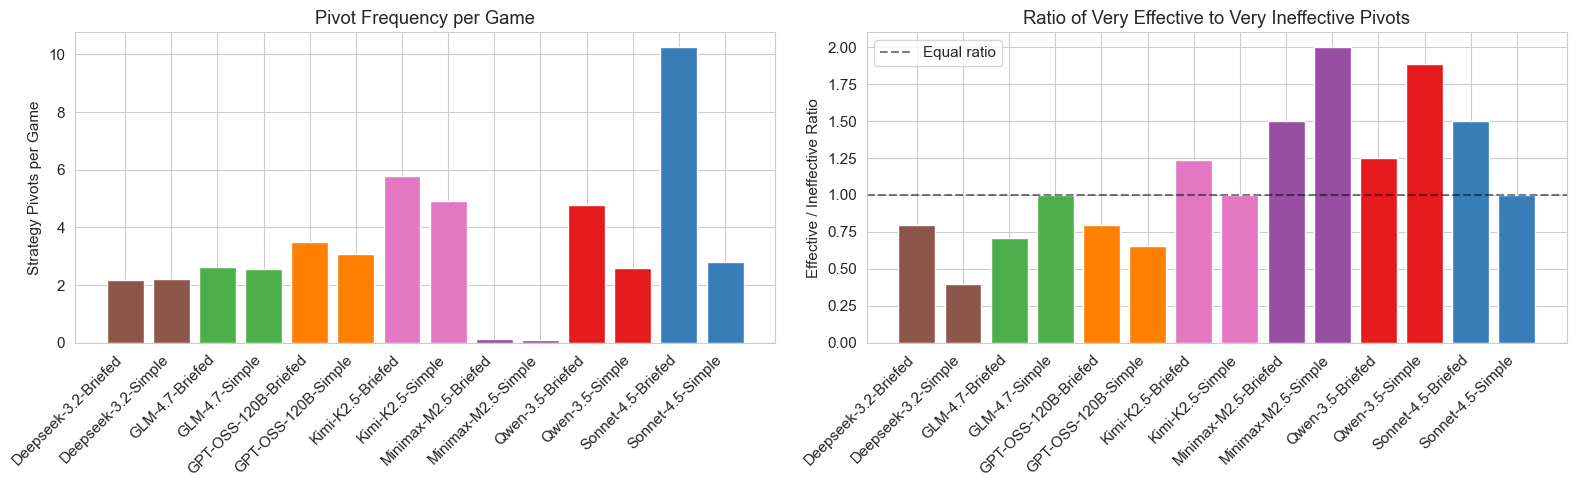

                      n_games  n_pivots  pivots_per_game  n_effective  n_ineffective  eff_ratio
player_type                                                                                    
Deepseek-3.2-Briefed      113       247         2.185841           12             15   0.800000
Deepseek-3.2-Simple       113       251         2.221239            6             15   0.400000
GLM-4.7-Briefed           179       470         2.625698           17             24   0.708333
GLM-4.7-Simple            179       458         2.558659           26             26   1.000000
GPT-OSS-120B-Briefed      145       505         3.482759           27             34   0.794118
GPT-OSS-120B-Simple       145       446         3.075862           23             35   0.657143
Kimi-K2.5-Briefed         167       963         5.766467           73             59   1.237288
Kimi-K2.5-Simple          167       822         4.922156           55             55   1.000000
Minimax-M2.5-Briefed      118        17 

In [3]:
games_per_model = df.groupby("player_type")["game_id"].nunique().rename("n_games")
pivot_counts = pivots.groupby("player_type").size().rename("n_pivots")
eff_counts = effective.groupby("player_type").size().rename("n_effective")
ineff_counts = ineffective.groupby("player_type").size().rename("n_ineffective")

freq = pd.concat([games_per_model, pivot_counts, eff_counts, ineff_counts], axis=1).fillna(0)
freq["pivots_per_game"] = freq["n_pivots"] / freq["n_games"]
freq["eff_ratio"] = freq["n_effective"] / freq["n_ineffective"].replace(0, np.nan)

player_order = sort_player_types(freq.index)
freq = freq.loc[player_order]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

colors = [get_player_color(pt) for pt in player_order]
ax1.bar(range(len(player_order)), freq["pivots_per_game"], color=colors)
ax1.set_xticks(range(len(player_order)))
ax1.set_xticklabels(player_order, rotation=45, ha="right")
ax1.set_ylabel("Strategy Pivots per Game")
ax1.set_title("Pivot Frequency per Game")

ax2.bar(range(len(player_order)), freq["eff_ratio"], color=colors)
ax2.axhline(1.0, color="black", linestyle="--", alpha=0.5, label="Equal ratio")
ax2.set_xticks(range(len(player_order)))
ax2.set_xticklabels(player_order, rotation=45, ha="right")
ax2.set_ylabel("Effective / Ineffective Ratio")
ax2.set_title("Ratio of Very Effective to Very Ineffective Pivots")
ax2.legend()

plt.tight_layout()
plt.show()

print(freq[["n_games", "n_pivots", "pivots_per_game",
            "n_effective", "n_ineffective", "eff_ratio"]].to_string())

## Section 2: Win Probability at Pivot Time

Distribution of predicted win probability at the moment of the pivot.
When on the probability scale do effective vs ineffective pivots occur?

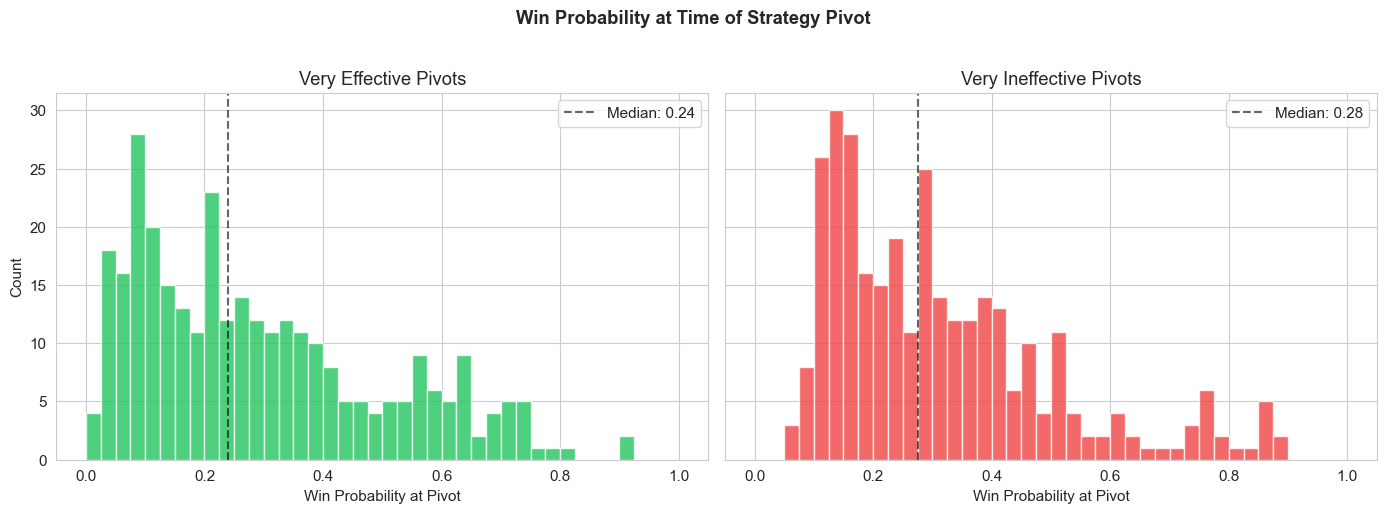

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

bins = np.linspace(0, 1, 41)

ax1.hist(effective["before_prob"], bins=bins, color="#22C55E", alpha=0.8, edgecolor="white")
ax1.set_xlabel("Win Probability at Pivot")
ax1.set_ylabel("Count")
ax1.set_title("Very Effective Pivots")
ax1.axvline(effective["before_prob"].median(), color="black", linestyle="--", alpha=0.6,
            label=f'Median: {effective["before_prob"].median():.2f}')
ax1.legend()

ax2.hist(ineffective["before_prob"], bins=bins, color="#EF4444", alpha=0.8, edgecolor="white")
ax2.set_xlabel("Win Probability at Pivot")
ax2.set_title("Very Ineffective Pivots")
ax2.axvline(ineffective["before_prob"].median(), color="black", linestyle="--", alpha=0.6,
            label=f'Median: {ineffective["before_prob"].median():.2f}')
ax2.legend()

fig.suptitle("Win Probability at Time of Strategy Pivot", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## Section 3: Flavor Changes by Target Strategy

What flavors change when pivoting **to** a given strategy? One comparison plot
per target strategy, with effective vs ineffective side by side.

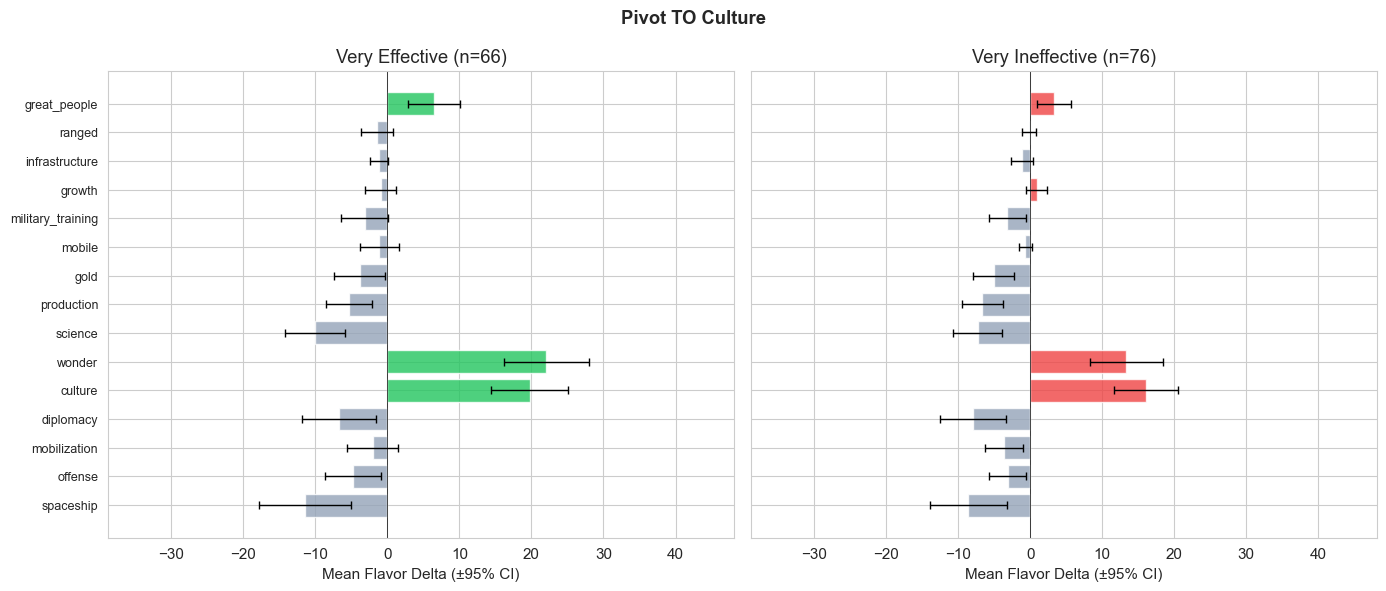

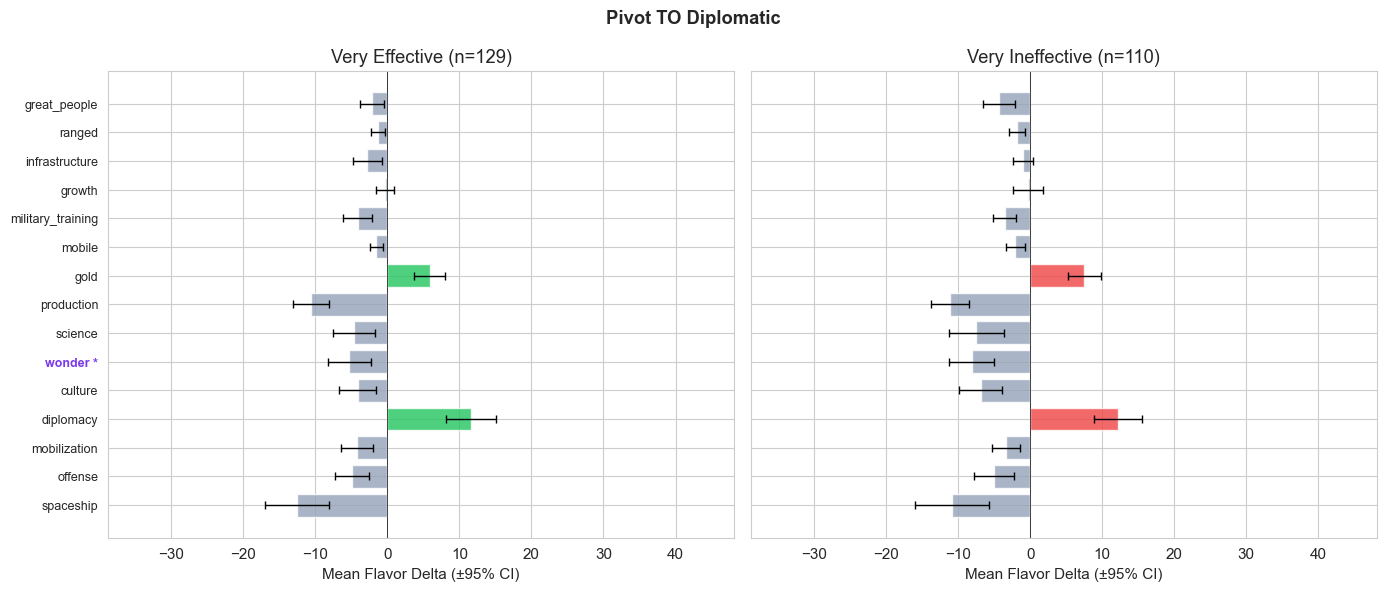

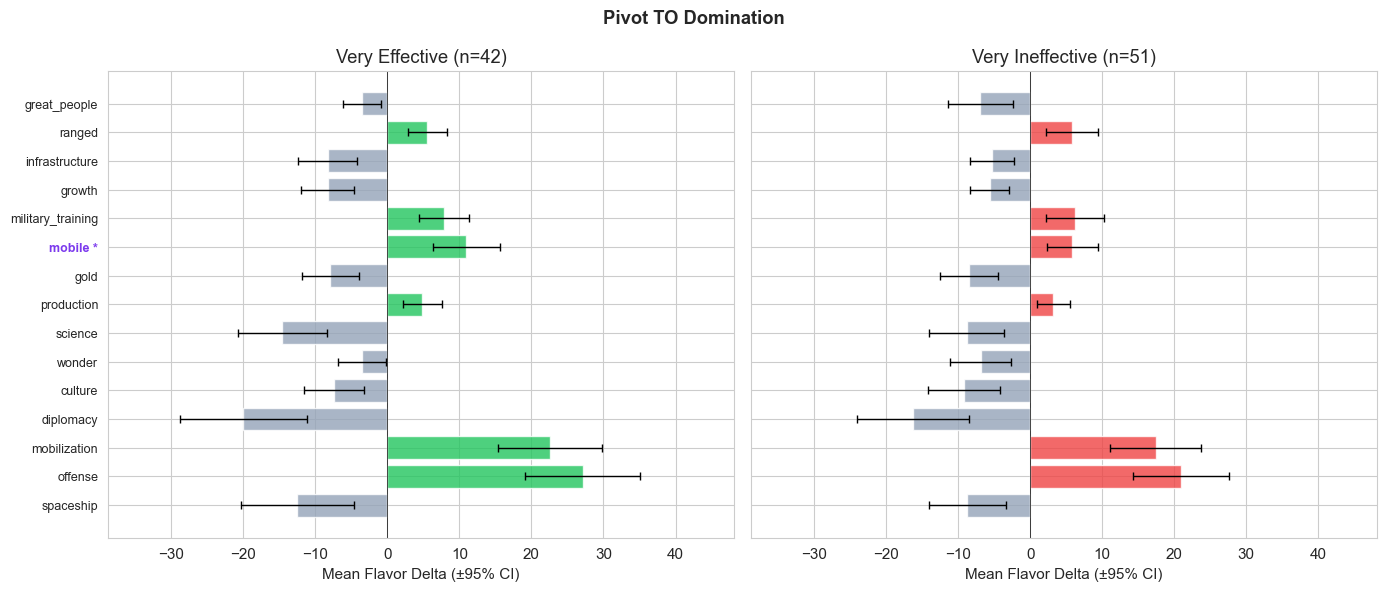

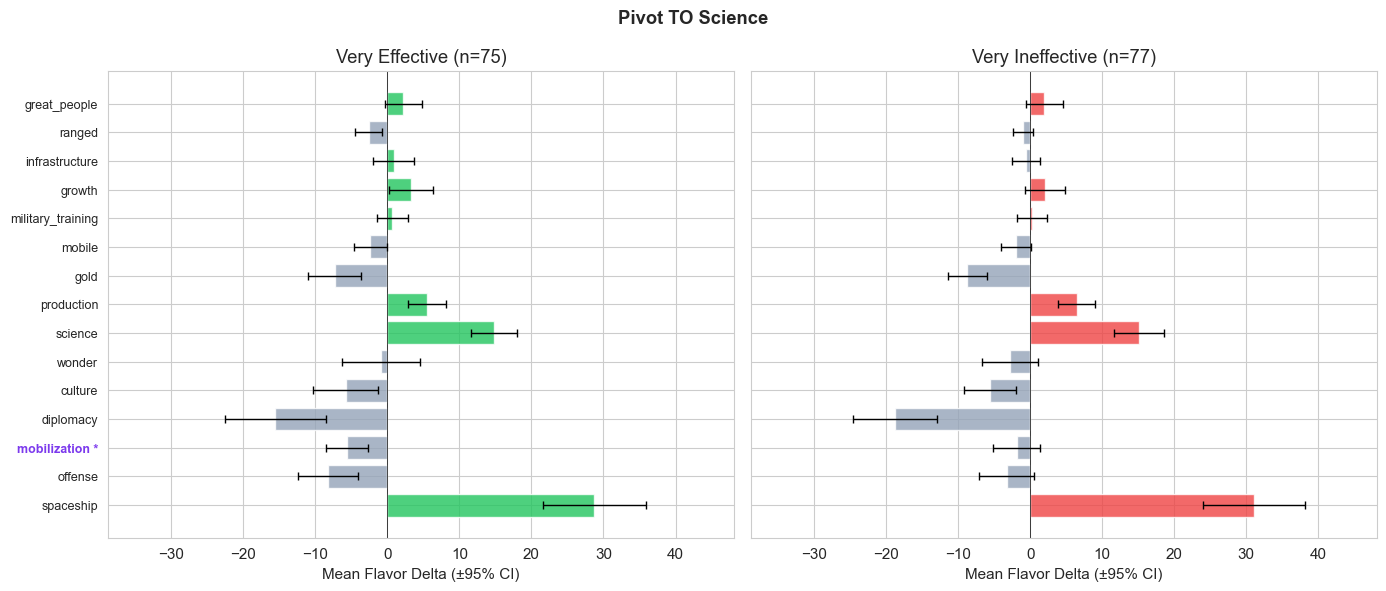

In [5]:
from scipy import stats

delta_cols = [f"{c}_delta" for c in flavor_cols]
flavor_short = [c.replace("flavor_", "") for c in flavor_cols]

# Select top flavors by max absolute mean delta across all strategy/class combos
all_means = extreme.groupby("strategy_filled")[delta_cols].mean().abs()
top_mask = all_means.max(axis=0).nlargest(15).index
top_idx = [delta_cols.index(c) for c in top_mask]
top_labels = [flavor_short[i] for i in top_idx]
top_dcols = list(top_mask)

target_strategies = sorted(pivots["strategy_filled"].dropna().unique())

# --- Pre-compute global x-axis limits across all strategies ---
global_xmin, global_xmax = 0.0, 0.0
for strat in target_strategies:
    for subset in [effective[effective["strategy_filled"] == strat],
                   ineffective[ineffective["strategy_filled"] == strat]]:
        if len(subset) >= 2:
            means = subset[top_dcols].mean().values
            sems = subset[top_dcols].sem().values
            lo = (means - 1.96 * sems).min()
            hi = (means + 1.96 * sems).max()
            global_xmin = min(global_xmin, lo)
            global_xmax = max(global_xmax, hi)
        elif len(subset) == 1:
            vals = subset[top_dcols].values[0]
            global_xmin = min(global_xmin, vals.min())
            global_xmax = max(global_xmax, vals.max())

pad = (global_xmax - global_xmin) * 0.15
global_xmin -= pad
global_xmax += pad

# --- Plot each strategy ---
for strat in target_strategies:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

    eff_sub = effective[effective["strategy_filled"] == strat]
    ineff_sub = ineffective[ineffective["strategy_filled"] == strat]

    # --- Compute significance stars between groups ---
    sig_stars = [""] * len(top_dcols)
    if len(eff_sub) >= 2 and len(ineff_sub) >= 2:
        for i, col in enumerate(top_dcols):
            _, p = stats.mannwhitneyu(
                eff_sub[col].dropna(), ineff_sub[col].dropna(),
                alternative="two-sided",
            )
            if p < 0.001:
                sig_stars[i] = " ***"
            elif p < 0.01:
                sig_stars[i] = " **"
            elif p < 0.05:
                sig_stars[i] = " *"

    y_labels = [f"{lbl}{star}" for lbl, star in zip(top_labels, sig_stars)]

    for ax, label, subset, color in [
        (ax1, "Very Effective", eff_sub, "#22C55E"),
        (ax2, "Very Ineffective", ineff_sub, "#EF4444"),
    ]:
        if len(subset) >= 2:
            vals = subset[top_dcols].mean()
            errs = 1.96 * subset[top_dcols].sem()
            bar_colors = [color if v > 0 else "#94A3B8" for v in vals.values]
            ax.barh(range(len(y_labels)), vals.values, xerr=errs.values,
                    color=bar_colors, alpha=0.8, capsize=3, error_kw={"linewidth": 1})
        elif len(subset) == 1:
            vals = subset[top_dcols].iloc[0]
            bar_colors = [color if v > 0 else "#94A3B8" for v in vals.values]
            ax.barh(range(len(y_labels)), vals.values, color=bar_colors, alpha=0.8)
        else:
            ax.text(0, len(y_labels) / 2, "No pivots", ha="center", va="center",
                    fontsize=12, color="gray")

        ax.set_yticks(range(len(y_labels)))
        ax.set_yticklabels(y_labels, fontsize=9)
        ax.axvline(0, color="black", linewidth=0.5)
        ax.set_xlabel("Mean Flavor Delta (±95% CI)")
        ax.set_title(f"{label} (n={len(subset)})")
        ax.set_xlim(global_xmin, global_xmax)

    # Color the star portions of y-tick labels purple
    for ax in (ax1, ax2):
        for tick_label, star in zip(ax.get_yticklabels(), sig_stars):
            if star:
                tick_label.set_color("#7C3AED")
                tick_label.set_fontweight("bold")

    fig.suptitle(f"Pivot TO {strat}", fontweight="bold")
    plt.tight_layout()
    plt.show()

## Section 4: Model Rationale

LLM rationale text for the most extreme pivots.

In [6]:
pd.set_option("display.max_colwidth", None)

for label, subset in [
    ("MOST EFFECTIVE", effective.nlargest(5, "win_prob_delta")),
    ("MOST INEFFECTIVE", ineffective.nsmallest(5, "win_prob_delta")),
]:
    print(f'\n{"="*80}')
    print(f" {label}")
    print(f'{"="*80}')
    for _, row in subset.iterrows():
        outcome = "Won" if row.get("is_winner") == 1 else "Lost"
        final_p = row.get("final_win_prob", float("nan"))
        vtype = row.get("victory_type", "N/A")
        vturn = int(row["victory_turn"]) if pd.notna(row.get("victory_turn")) else "N/A"
        print(f'\n{row["player_type"]} \u00b7 {row["civilization"]} \u00b7 Turn {int(row["turn"])}')
        print(f'Strategy: {row["prev_strategy"]} \u2192 {row["strategy_filled"]}')
        print(f'Win prob: {row["before_prob"]:.3f} \u2192 {row["after_prob"]:.3f} (delta={row["win_prob_delta"]:+.3f})')
        print(f'Outcome: {outcome} (final prob: {final_p:.3f}) \u00b7 {vtype} victory on turn {vturn}')
        rationale = str(row.get("rationale", "")).replace("\n", " ").strip()
        print(f"> {rationale[:400]}..." if len(rationale) > 400 else f"> {rationale}")


 MOST EFFECTIVE

Kimi-K2.5-Simple · Germany · Turn 279
Strategy: Domination → Diplomatic
Win prob: 0.325 → 0.778 (delta=+0.453)
Outcome: Won (final prob: 1.000) · Diplomatic victory on turn 448
> Turn 280: Captured Opis from Babylon, significantly weakening them. America poses existential military threat (2356 vs 1914 strength) requiring maintained defensive posture. Shifting Grand Strategy to UnitedNations - currently leading with 21/45 delegates (46%). Must secure diplomatic victory before America expands further. Reduced Offense to 50 as Babylon/Polynesia wars wind down; increased Naval...

Deepseek-3.2-Simple · The Ottomans · Turn 327
Strategy: Science → Culture
Win prob: 0.489 → 0.846 (delta=+0.357)
Outcome: Won (final prob: 0.786) · Cultural victory on turn 412
> We are on the cusp of a Cultural Victory, having 3 influential civs (Denmark, Venice, Korea) and Songhai 6 turns away. Austria remains our primary competitor and needs to be overtaken. To accelerate, we are switching Gr

## Export

In [7]:
export_pivot_markdown(extreme, "pivot_rationale", flavor_cols)
export_pivot_csv(extreme, "pivot_rationale/extreme_pivots.csv", flavor_cols)

Written: pivot_rationale/Deepseek-3.2-Briefed.md
Written: pivot_rationale/Deepseek-3.2-Simple.md
Written: pivot_rationale/GLM-4.7-Briefed.md
Written: pivot_rationale/GLM-4.7-Simple.md
Written: pivot_rationale/GPT-OSS-120B-Briefed.md
Written: pivot_rationale/GPT-OSS-120B-Simple.md
Written: pivot_rationale/Kimi-K2.5-Briefed.md
Written: pivot_rationale/Kimi-K2.5-Simple.md
Written: pivot_rationale/Minimax-M2.5-Briefed.md
Written: pivot_rationale/Minimax-M2.5-Simple.md
Written: pivot_rationale/Qwen-3.5-Briefed.md
Written: pivot_rationale/Qwen-3.5-Simple.md
Written: pivot_rationale/Sonnet-4.5-Briefed.md
Written: pivot_rationale/Sonnet-4.5-Simple.md
Written: pivot_rationale/extreme_pivots.csv  (626 rows)


## Summary Statistics

In [8]:
total = pivots.groupby("player_type").size().rename("total_pivots")
n_eff = effective.groupby("player_type").size().rename("n_effective")
n_ineff = ineffective.groupby("player_type").size().rename("n_ineffective")
med_eff = effective.groupby("player_type")["win_prob_delta"].median().rename("median_eff_delta")
med_ineff = ineffective.groupby("player_type")["win_prob_delta"].median().rename("median_ineff_delta")

summary = pd.concat(
    [games_per_model, total, n_eff, n_ineff, med_eff, med_ineff], axis=1
).fillna(0)
summary["pivots_per_game"] = summary["total_pivots"] / summary["n_games"]
summary = summary.loc[sort_player_types(summary.index)]
print(summary.to_string())

                      n_games  total_pivots  n_effective  n_ineffective  median_eff_delta  median_ineff_delta  pivots_per_game
player_type                                                                                                                   
Deepseek-3.2-Briefed      113           247           12             15          0.080913           -0.097633         2.185841
Deepseek-3.2-Simple       113           251            6             15          0.221973           -0.062085         2.221239
GLM-4.7-Briefed           179           470           17             24          0.082237           -0.084219         2.625698
GLM-4.7-Simple            179           458           26             26          0.082722           -0.080750         2.558659
GPT-OSS-120B-Briefed      145           505           27             34          0.072472           -0.076852         3.482759
GPT-OSS-120B-Simple       145           446           23             35          0.089696           -0.098823  